# 02 · Re-check after cleaning

Day 2 check: did the cleaning rules do what we expect, and does every model have enough training data in every split?

1. Rows changed by each rule (from the database's `meta` table)
2. Currency caps and the films flagged as `money_suspect`
3. Training-view sizes per model and split, plus the **gate**
4. Training rows per decade
5. Plots: budget vs revenue in 2025 dollars, score distribution

Reads `data/movies.db` (build it with `make db`). **The test split stays locked:** it's counted here, but its money and scores are never plotted or summarised.

In [1]:
import json
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "movies.db"
con = sqlite3.connect(f"file:{DB_PATH.as_posix()}?mode=ro", uri=True)


def sql(query, **params):
    return pd.read_sql_query(query, con, params=params)


meta = {k: json.loads(v) for k, v in con.execute("SELECT key, value FROM meta")}
report = meta["cleaning_report"]
print("built:", meta["built_at"], "| source:", meta["source_file"], "| CPI base year:", meta["cpi_base_year"],
      "| vote threshold:", meta["vote_threshold"], "| splits:", meta["splits"])

built: 2026-10-21T10:20:11+00:00 | source: data/raw/tmdb_movies.jsonl | CPI base year: 2025 | vote threshold: 50 | splits: {'train': '<=2015', 'validation': '2016-2018', 'test': '>=2019'}


## 1. Rows changed by each rule

In [2]:
rules = {k: v for k, v in report.items() if k != "currency_caps_2025_usd"}
films = report["films"]
rule_table = pd.DataFrame({"rows": rules}).assign(pct_of_films=lambda d: (100 * d["rows"] / films).round(2))
rule_table

,rows,pct_of_films
raw_records,79199,100.00
duplicate_ids_dropped,0,0.00
not_released_dropped,0,0.00
title_from_original_title,0,0.00
release_date_unparseable,0,0.00
runtime_nulled,1238,1.56
score_nulled_no_votes,0,0.00
no_split_missing_year,0,0.00
budget_zero_or_missing,64566,81.52
budget_placeholder_nulled,167,0.21


## 2. Currency caps and suspect money

Each non-English film's 2025-dollar budget is compared with 3× the 99th percentile of its language's *other* budgets
(languages with fewer than 30 budgets use all other non-English budgets). The caps below are over all budgets, for reference.

In [3]:
caps = pd.Series(report["currency_caps_2025_usd"], name="cap_2025_usd_millions") / 1e6
counts = sql("""
    SELECT original_language AS language, COUNT(*) AS budgets, MAX(budget_2025) / 1e6 AS max_budget_2025_millions
    FROM movies WHERE original_language != 'en' AND budget IS NOT NULL GROUP BY original_language
""").set_index("language")
cap_table = counts.join(caps, how="right").sort_values("cap_2025_usd_millions").round(1)
cap_table.loc["other non-English", "budgets"] = counts.drop(index=cap_table.index, errors="ignore")["budgets"].sum()
cap_table

,budgets,max_budget_2025_millions,cap_2025_usd_millions
ro,30.0,12.0,34.9
fi,66.0,32.5,57.9
tr,48.0,22.5,58.2
ml,39.0,23.8,68.2
nl,54.0,33.6,73.8
pl,38.0,32.7,79.4
da,55.0,33.7,85.3
pt,70.0,52.8,85.8
no,52.0,37.6,107.3
es,318.0,69.3,127.5


In [4]:
# For currency flags, own_cap_m is the cap the film was actually compared with: computed without its own budget,
# which is why a film can be flagged below the all-budgets cap in the table above.
foreign = sql("SELECT id, original_language AS lang, budget_2025 FROM movies WHERE original_language != 'en' AND budget IS NOT NULL")
own_language = set(caps.index) - {"other non-English"}


def own_cap(film):
    others = foreign[foreign["id"] != film["id"]]
    if film["lang"] in own_language:
        others = others[others["lang"] == film["lang"]]
    return round(3 * others["budget_2025"].quantile(0.99) / 1e6, 1)


suspect = sql("""
    SELECT id, title, year, original_language AS lang, budget, revenue,
           ROUND(budget_2025 / 1e6, 1) AS budget_2025_m, money_suspect_reason AS reason, split
    FROM movies WHERE money_suspect ORDER BY reason, year
""")
suspect["own_cap_m"] = [own_cap(f) if f["reason"] == "currency" else None for _, f in suspect.iterrows()]
suspect

,id,title,year,lang,budget,revenue,budget_2025_m,reason,split,own_cap_m
0,29266,War and Peace,1968,ru,700000000,14000000,6483.3,currency,train,213.3
1,78827,Deewangee,2002,hi,220000000,992178,394.0,currency,train,226.3
2,372519,The Ten Commandments: The Movie,2016,pt,39307171,37070177,52.8,currency,validation,45.7
3,174645,Java Heat,2013,en,15000000,1061,20.7,low_ratio,train,NaN
4,906126,Society of the Snow,2023,es,65500000,1281,69.3,low_ratio,test,NaN
5,763215,Damsel,2024,en,60000000,5000,61.6,low_ratio,test,NaN


## 3. Training-view sizes and the gate

The gate asks for at least **5,000 train, 500 validation and 500 test** films per model. If a view falls short, we stop and decide a fix before Day 3.

In [5]:
GATE = {"train": 5_000, "validation": 500, "test": 500}
views = {"revenue": "v_train_revenue", "budget": "v_train_budget", "score": "v_train_score"}

sizes = pd.DataFrame({
    model: sql(f"SELECT split, COUNT(*) AS n FROM {view} GROUP BY split").set_index("split")["n"]
    for model, view in views.items()
}).T[list(GATE)]
sizes["all"] = sizes.sum(axis=1)
sizes.loc["all films"] = sql("SELECT split, COUNT(*) AS n FROM movies GROUP BY split").set_index("split")["n"]
sizes.loc["all films", "all"] = films

gate = sizes.loc[list(views), list(GATE)].ge(pd.Series(GATE))
print("gate passed for every model and split:", bool(gate.all().all()))
sizes.astype("Int64")

gate passed for every model and split: True


split,train,validation,test,all
revenue,8050,886,1485,10421
budget,11334,1162,1964,14460
score,22016,3600,7461,33077
all films,67199,3600,8400,79199


In [6]:
assert gate.all().all(), f"training view too small:\n{gate}"

## 4. Training rows per decade (train and validation only)

In [7]:
decade = "(year / 10) * 10"
per_decade = pd.DataFrame({
    model: sql(f"SELECT {decade} AS decade, COUNT(*) AS n FROM {view} WHERE split != 'test' GROUP BY decade")
    .set_index("decade")["n"]
    for model, view in views.items()
})
per_decade["all films"] = sql(f"SELECT {decade} AS decade, COUNT(*) AS n FROM movies WHERE split != 'test' GROUP BY decade").set_index("decade")["n"]
per_decade["revenue_pct"] = (100 * per_decade["revenue"] / per_decade["all films"]).round(1)
per_decade

,revenue,budget,score,all films,revenue_pct
decade,,,,,
1960,286,519,1351,12000,2.4
1970,471,860,1794,12000,3.9
1980,1074,1451,2570,12000,9.0
1990,1627,2115,3440,12000,13.6
2000,2744,3790,6447,11999,22.9
2010,2734,3761,10014,10800,25.3


## 5. Plots (train and validation only)

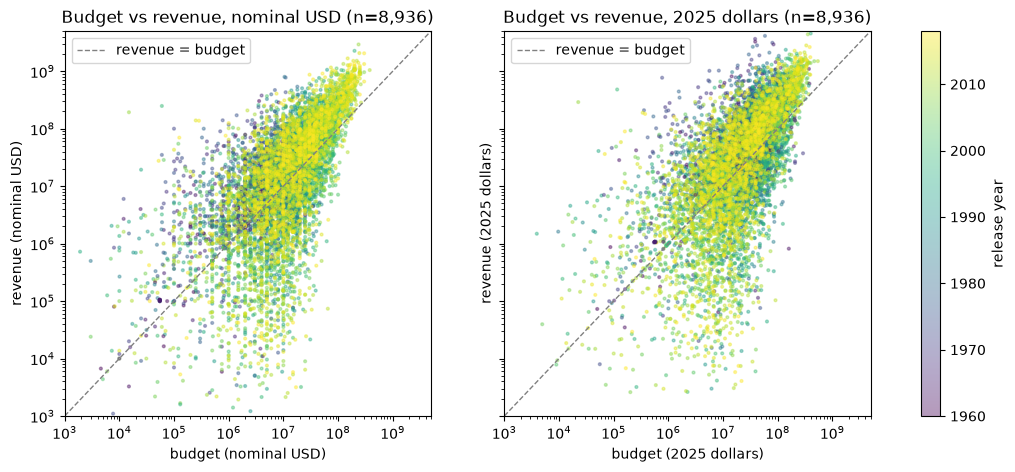

revenue/budget: median 1.71x, 10th pct 0.14x, 90th pct 8.07x
films earning less than their budget: 36%


In [8]:
money = sql("SELECT year, budget, revenue, budget_2025, revenue_2025 FROM v_train_revenue WHERE split != 'test'")

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, (b, r, label) in zip(axes, [("budget", "revenue", "nominal USD"), ("budget_2025", "revenue_2025", "2025 dollars")]):
    sc = ax.scatter(money[b], money[r], c=money["year"], s=4, alpha=0.4, cmap="viridis")
    lims = [1e3, 5e9]
    ax.plot(lims, lims, color="grey", lw=1, ls="--", label="revenue = budget")
    ax.set(xscale="log", yscale="log", xlim=lims, ylim=[1e3, 5e9], xlabel=f"budget ({label})", ylabel=f"revenue ({label})",
           title=f"Budget vs revenue, {label} (n={len(money):,})")
    ax.legend(loc="upper left")
fig.colorbar(sc, ax=axes, label="release year")
plt.show()

ratio = money["revenue_2025"] / money["budget_2025"]
print(f"revenue/budget: median {ratio.median():.2f}x, 10th pct {ratio.quantile(0.1):.2f}x, 90th pct {ratio.quantile(0.9):.2f}x")
print(f"films earning less than their budget: {100 * (ratio < 1).mean():.0f}%")

In [9]:
older = money[money["year"] < 1990]
newer = money[money["year"] >= 2000]
print(f"median budget, 2025 dollars: before 1990 ${older['budget_2025'].median() / 1e6:.1f}M (nominal ${older['budget'].median() / 1e6:.1f}M), "
      f"2000+ ${newer['budget_2025'].median() / 1e6:.1f}M (nominal ${newer['budget'].median() / 1e6:.1f}M)")

median budget, 2025 dollars: before 1990 $24.4M (nominal $5.5M), 2000+ $21.8M (nominal $15.0M)


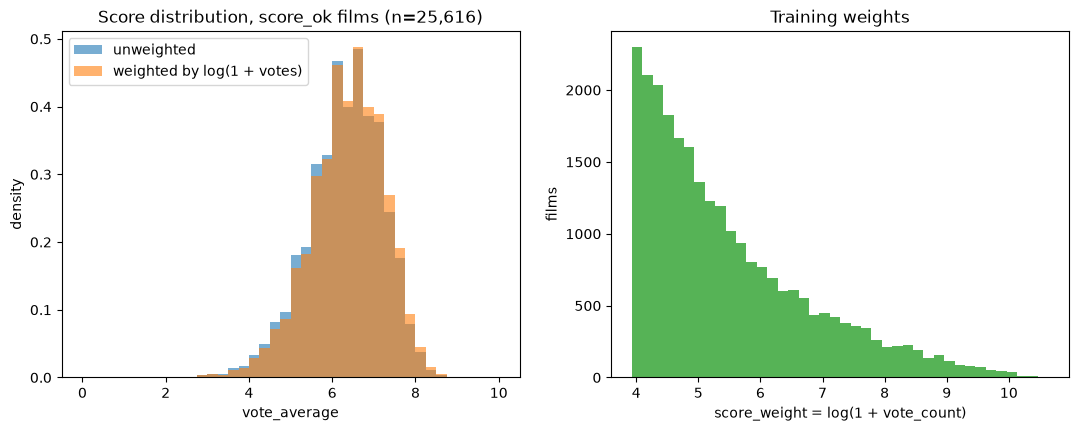

score mean: unweighted 6.30, weighted 6.36; std 0.90
by split: {'train': {'count': 22016, 'mean': 6.3, 'std': 0.9}, 'validation': {'count': 3600, 'mean': 6.32, 'std': 0.86}}


In [10]:
score = sql("SELECT vote_average, vote_count, score_weight, split FROM v_train_score WHERE split != 'test'")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.arange(0, 10.25, 0.25)
axes[0].hist(score["vote_average"], bins=bins, alpha=0.6, density=True, label="unweighted")
axes[0].hist(score["vote_average"], bins=bins, weights=score["score_weight"], alpha=0.6, density=True, label="weighted by log(1 + votes)")
axes[0].set(xlabel="vote_average", ylabel="density", title=f"Score distribution, score_ok films (n={len(score):,})")
axes[0].legend()
axes[1].hist(score["score_weight"], bins=40, color="tab:green", alpha=0.8)
axes[1].set(xlabel="score_weight = log(1 + vote_count)", ylabel="films", title="Training weights")
plt.show()

w = score["score_weight"]
print(f"score mean: unweighted {score['vote_average'].mean():.2f}, weighted {np.average(score['vote_average'], weights=w):.2f}; "
      f"std {score['vote_average'].std():.2f}")
print("by split:", score.groupby("split")["vote_average"].agg(["count", "mean", "std"]).round(2).to_dict("index"))

## Findings

_From `data/movies.db`, built 2026-10-21 from the full pull: 79,199 films, 1,200 per year._

**Gate: passed.** Every model has at least 5,000 train, 500 validation and 500 test films.

| Model | Train | Validation | Test |
| --- | --- | --- | --- |
| Revenue | 8,050 | 886 | 1,485 |
| Budget | 11,334 | 1,162 | 1,964 |
| Score | 22,016 | 3,600 | 7,461 |

**1. The rules hit what we expected.**
- Set to NULL: 1,238 runtimes (0 or over 600 minutes), 167 placeholder budgets and 151 placeholder revenues (under $1,000).
- 6 films are `money_suspect` and stay in the database for browsing:
  - currency: War and Peace (1968, ru), *Deewangee* (2002, hi, $220M) and The Ten Commandments: The Movie (2016, pt), which was accepted as a borderline flag
  - low ratio: *Java Heat*, Society of the Snow and Damsel
- No duplicates, unreleased films, missing dates or 0-vote scores. `revenue_incomplete` flags 0 films, as expected for this pull.
- 23 languages now have enough budgets for their own cap, which ranges from $35M to $546M.

**2. The 2025-dollar conversion works.**
- The median budget before 1990 is $5.5M nominal but $24.4M in 2025 dollars, close to the 2000+ median of $21.8M.
- In the plot, older films join the main cloud instead of sitting lower left.

**3. Revenue training is thin before 1980.**
- Revenue films: 286 in the 1960s and 471 in the 1970s, against about 2,700 per decade in the 2000s and 2010s.
- The extra 500 films per year added only 15 and 13 revenue films to those two decades.

**4. The score data is solid.**
- Mean score 6.30 (train) and 6.32 (validation), with standard deviations of 0.90 and 0.86.
- Weighting by log(1 + votes) moves the distribution only slightly towards higher scores.
- Validation grew from 2,100 to 3,600 score films. The test split is counted but never plotted.

**5. Some revenues look incomplete. Not fixed; for the README's Limitations and Day 4.**
- 178 training films (2.0%) earned less than 1% of their budget.
- Some are real flops (*Foodfight!*, *The Sunchaser*). Others look like only part of the box office was recorded, probably just the US share: *Flying Swords of Dragon Gate* shows $128k despite being a hit in China.
- 36% of training films earn less than their budget overall. The median ratio is 1.71×.

**6. How the caps work, as a reminder.**
- A flagged film is compared with the cap computed *without* its own budget, shown as `own_cap_m`: $213M for War and Peace, $226M for *Deewangee* and $45.7M for The Ten Commandments.
- The per-language caps in the table include every budget, so they're higher.

**Verdict.** The database is ready for Day 3: all three training views are large enough in every split.